# Exploratory Data Analysis of the Brain Tumour MRI Dataset

**Course:** DS 4889 Machine Learning, United International University

**Course outcomes addressed:** CO1 (data acquisition and integration) and CO2 (exploratory data analysis and data quality assessment)

**Dataset:** Kaggle repository masoudnickparvar/brain-tumor-mri-dataset, comprising 7200 magnetic resonance images distributed across four diagnostic categories: glioma, meningioma, no tumour and pituitary adenoma. Many published descriptions of this dataset quote 7023 images with unequal class counts; those figures refer to an earlier revision. The counts computed below are authoritative for the copy present in the data folder.

## Objective

This notebook documents the first stage of the project pipeline: acquisition of the brain tumour magnetic resonance imaging corpus and a systematic inspection of its properties before any model is fitted. The overarching research question of the project is whether unsupervised Gaussian mixture pre-segmentation improves the classification accuracy of a convolutional neural network. A comparative claim of that kind is only credible if the underlying data are first shown to be complete, correctly organised and adequately characterised, because an undetected defect in the corpus would propagate silently into every downstream comparison and would be indistinguishable from a genuine effect of the segmentation stage.

The analysis is therefore not presented as a preliminary formality. Each result below is translated into an explicit, traceable decision governing preprocessing, evaluation metrics and model architecture, and those decisions are collected in the closing summary.

## Course outcome mapping

**CO1, data acquisition and integration.** The dataset is obtained from the public Kaggle repository, verified against the expected directory contract of data/Training/<class> and data/Testing/<class>, and summarised quantitatively so that the exact corpus used in later notebooks is unambiguously recorded.

**CO2, exploratory data analysis and data quality assessment.** Class balance, raw image geometry and pixel intensity behaviour are examined using descriptive statistics, visualisation and a formal hypothesis test, and the practical consequences of each finding are stated.

## Questions addressed by this notebook

1. How many images does the corpus contain, and how are they allocated between the training and testing partitions?
2. Are the four diagnostic classes balanced, and if not, how severe is the imbalance and what does it imply for the choice of performance metric?
3. Are the source images uniform in spatial resolution, and would resizing to a single network input size distort the aspect ratio of the anatomy?
4. Do the intensity distributions of the four classes differ sufficiently for raw intensity alone to serve as a discriminative feature, or is a spatially aware model required?

In [1]:
import sys

# The reusable project code lives in the sibling 'src' package. Adding the
# parent directory to the module search path keeps the notebook consistent with
# the training scripts, which import exactly the same implementations.
sys.path.append('..')

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats

from src import config, data_loader, preprocessing

# A single fixed seed governs every random subsample reported below, so that a
# reader re-running the notebook obtains the identical figures and statistics.
np.random.seed(config.RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print("Project root:", config.PROJECT_ROOT)
print("Data directory:", config.DATA_DIR)
print("Figure output directory:", config.FIGURES_DIR)
print("Target input size:", config.IMAGE_SIZE)
print("Random seed:", config.RANDOM_SEED)
print("Classes:", config.CLASS_LABELS)

Project root: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection
Data directory: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\data
Figure output directory: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures
Target input size: 224
Random seed: 42
Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset integrity check

Before any statistic is computed, the folder hierarchy is verified against the contract that the rest of the codebase assumes. This step is performed first because the most damaging data faults in an image classification project are silent rather than noisy: a misspelled class folder, an incompletely extracted archive or a partially downloaded partition does not raise an exception. It simply yields a class with fewer images than expected, and the resulting bias is then attributed, incorrectly, to the model.

The function verify_dataset raises an explicit FileNotFoundError when a split is missing and otherwise returns one row per split and class, including a boolean indicating whether the folder exists. Failing loudly at this point is far cheaper than discovering an inconsistency after several hours of training.

In [2]:
inventory = data_loader.verify_dataset()
display(inventory)

total_images = int(inventory["image_count"].sum())
train_total = int(inventory.loc[inventory["split"] == "Training", "image_count"].sum())
test_total = int(inventory.loc[inventory["split"] == "Testing", "image_count"].sum())

print(f"Total images discovered: {total_images}")
print(f"Training partition: {train_total} images")
print(f"Testing partition: {test_total} images")
print(f"Testing partition as a share of the corpus: {100.0 * test_total / total_images:.2f} per cent")

# An empty or missing class folder must be surfaced explicitly rather than
# being absorbed silently into a smaller class count.
missing = inventory.loc[(~inventory["exists"]) | (inventory["image_count"] == 0)]
if len(missing):
    print("Warning: the following class folders are missing or empty.")
    display(missing)
else:
    print("Integrity check passed: all eight expected class folders exist and contain images.")

,split,class,label,image_count,exists
0,Training,glioma,Glioma,1400,True
1,Training,meningioma,Meningioma,1400,True
2,Training,notumor,No Tumor,1400,True
3,Training,pituitary,Pituitary,1400,True
4,Testing,glioma,Glioma,400,True
5,Testing,meningioma,Meningioma,400,True
6,Testing,notumor,No Tumor,400,True
7,Testing,pituitary,Pituitary,400,True


Total images discovered: 7200
Training partition: 5600 images
Testing partition: 1600 images
Testing partition as a share of the corpus: 22.22 per cent
Integrity check passed: all eight expected class folders exist and contain images.


## Class distribution

The relative frequency of the four classes determines both how performance should be measured and how the loss should be weighted during training. If one class is materially more frequent than the others, overall accuracy becomes a misleading summary, because a degenerate classifier that favours the majority class can attain a respectable accuracy while failing on the clinically important minority categories. The macro averaged and weighted F1 scores do not share that defect, since they aggregate per class precision and recall rather than counting correct predictions.

Imbalance also affects optimisation. Gradient contributions are proportional to class frequency, so a minority class exerts proportionally less influence on the learned decision boundary. The function compute_class_weights in the data loading module counteracts this by applying inverse frequency weights normalised to a mean of one, which rebalances the effective contribution of each class without altering the effective learning rate. The magnitude of the imbalance quantified below determines whether that correction is necessary.

In [3]:
# One row per class, one column per partition, which is the form required for
# the grouped bar chart and for the imbalance calculation.
counts = inventory.pivot(index="label", columns="split", values="image_count")
counts = counts.reindex(config.CLASS_LABELS)[["Training", "Testing"]]

counts["Total"] = counts["Training"] + counts["Testing"]
counts["Share of corpus (%)"] = (100.0 * counts["Total"] / counts["Total"].sum()).round(2)
counts["Share of training (%)"] = (100.0 * counts["Training"] / counts["Training"].sum()).round(2)

display(counts)

print("Expected share under perfect balance: "
      f"{100.0 / config.NUM_CLASSES:.2f} per cent per class")

split,Training,Testing,Total,Share of corpus (%),Share of training (%)
label,,,,,
Glioma,1400,400,1800,25.0,25.0
Meningioma,1400,400,1800,25.0,25.0
No Tumor,1400,400,1800,25.0,25.0
Pituitary,1400,400,1800,25.0,25.0


Expected share under perfect balance: 25.00 per cent per class


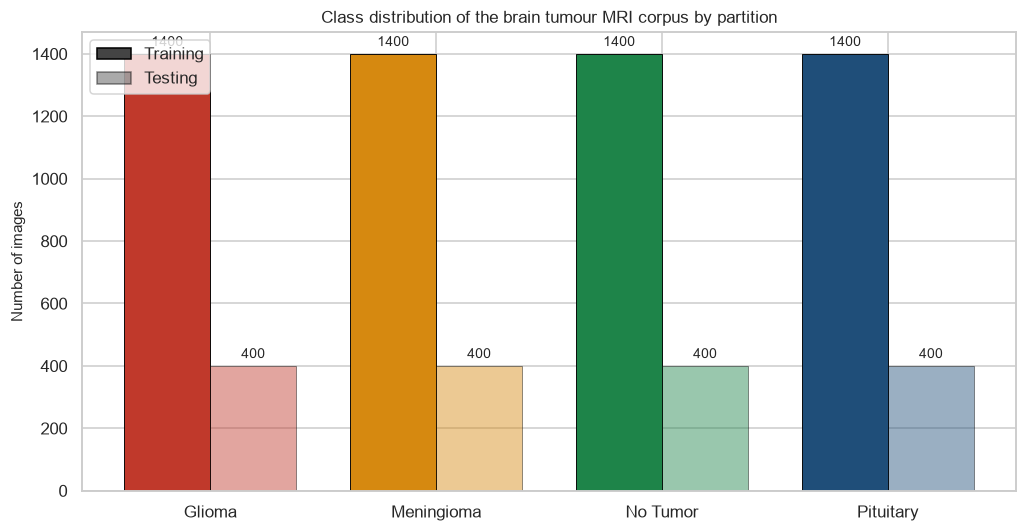

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\eda_class_distribution.png
Largest training class: Glioma with 1400 images
Smallest training class: Glioma with 1400 images
Imbalance ratio (largest divided by smallest): 1.00
Inverse frequency class weights that would be applied during training:
  Glioma       1.000
  Meningioma   1.000
  No Tumor     1.000
  Pituitary    1.000


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 5))

positions = np.arange(len(config.CLASS_LABELS))
bar_width = 0.38
train_counts = counts["Training"].to_numpy()
test_counts = counts["Testing"].to_numpy()

ax.bar(positions - bar_width / 2, train_counts, bar_width,
       color=config.CLASS_COLORS, edgecolor="black", linewidth=0.6)
ax.bar(positions + bar_width / 2, test_counts, bar_width,
       color=config.CLASS_COLORS, edgecolor="black", linewidth=0.6, alpha=0.45)

for position, train_value, test_value in zip(positions, train_counts, test_counts):
    ax.text(position - bar_width / 2, train_value + 25, str(int(train_value)),
            ha="center", fontsize=9)
    ax.text(position + bar_width / 2, test_value + 25, str(int(test_value)),
            ha="center", fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(config.CLASS_LABELS)
ax.set_ylabel("Number of images")
ax.set_title("Class distribution of the brain tumour MRI corpus by partition")

# Colour encodes the diagnostic class and opacity encodes the partition, so the
# legend is constructed explicitly rather than inferred from the bar artists.
ax.legend(handles=[Patch(facecolor="#444444", edgecolor="black", label="Training"),
                   Patch(facecolor="#444444", edgecolor="black", alpha=0.45, label="Testing")],
          loc="upper left", frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "eda_class_distribution.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

training_counts = counts["Training"]
imbalance_ratio = float(training_counts.max()) / float(training_counts.min())

print(f"Largest training class: {training_counts.idxmax()} "
      f"with {int(training_counts.max())} images")
print(f"Smallest training class: {training_counts.idxmin()} "
      f"with {int(training_counts.min())} images")
print(f"Imbalance ratio (largest divided by smallest): {imbalance_ratio:.2f}")

weights = data_loader.compute_class_weights(
    np.repeat(np.arange(config.NUM_CLASSES), training_counts.to_numpy())
)
print("Inverse frequency class weights that would be applied during training:")
for index, weight in weights.items():
    print(f"  {config.CLASS_LABELS[index]:<12} {weight:.3f}")

## Representative samples

Numerical summaries cannot reveal defects such as inverted contrast, duplicated slices, corrupted files, burnt in annotations or scans acquired in an unexpected anatomical plane. Direct visual inspection is therefore an indispensable complement to the tabular summary, and it also builds the domain intuition required to interpret the segmentation results in the second notebook.

Four images are drawn at random from each class using the fixed seed, so the panel is reproducible rather than cherry picked. The purpose is to confirm that the images are genuine axial, coronal or sagittal magnetic resonance slices, that the intensity convention is consistent, and to form an initial expectation of how visually distinct the four categories are.

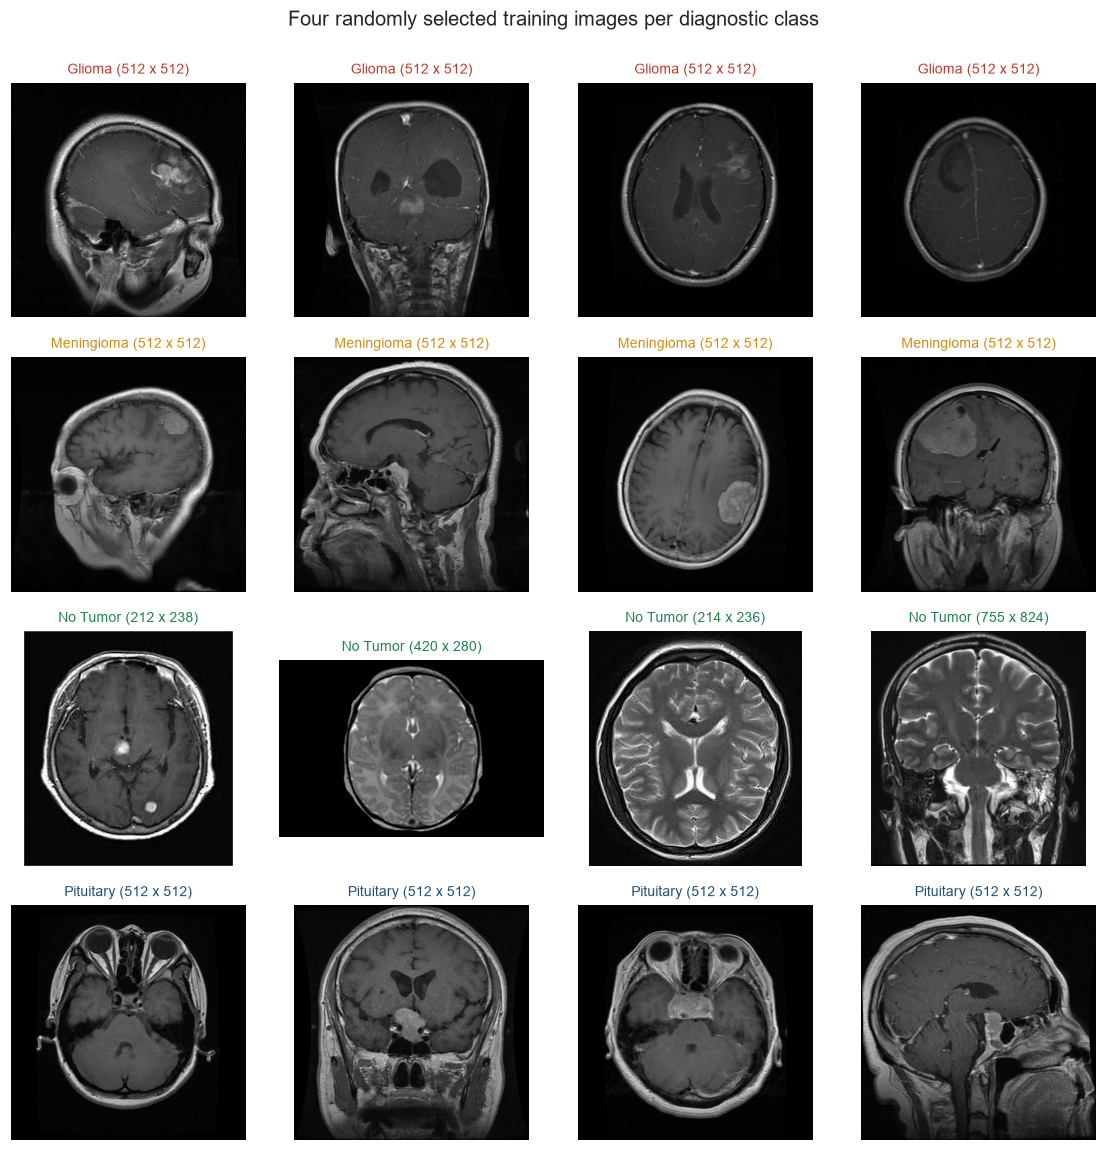

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\eda_sample_images.png


In [5]:
rng = np.random.default_rng(config.RANDOM_SEED)

fig, axes = plt.subplots(4, 4, figsize=(10.5, 10.5))

for row, class_name in enumerate(config.CLASS_FOLDERS):
    class_files = data_loader.list_image_files(config.TRAIN_DIR / class_name)
    chosen = rng.choice(len(class_files), size=4, replace=False)

    for column, file_index in enumerate(chosen):
        # Images are read in grayscale because the source scans are single
        # channel; any colour present in the files is a storage artefact.
        image = cv2.imread(str(class_files[file_index]), cv2.IMREAD_GRAYSCALE)
        ax = axes[row, column]
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{config.CLASS_LABELS[row]} ({image.shape[1]} x {image.shape[0]})",
                     fontsize=9, color=config.CLASS_COLORS[row])
        ax.axis("off")

fig.suptitle("Four randomly selected training images per diagnostic class", fontsize=13, y=0.995)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "eda_sample_images.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

## Image geometry

A convolutional network with fully connected classification layers requires a fixed input tensor shape, so every image must be resized to a common resolution; this project uses 224 by 224 pixels, which matches the input expected by the standard ImageNet pretrained backbones used for the transfer learning comparison. The relevant question is not whether resizing is necessary but what it costs.

If the source images share a single square resolution, resizing is a pure scaling operation and the anatomy is preserved. If instead the aspect ratios vary, forcing a square output stretches the brain along one axis, which alters the apparent shape of a lesion. Since lesion morphology is one of the cues that distinguishes a meningioma from a pituitary adenoma, any systematic distortion is a potential confounder and must be quantified rather than assumed away.

A sample of 600 files is inspected rather than the full training partition, because reading the header of every file would be needlessly slow while a sample of this size is more than sufficient to characterise the resolution distribution.

File paths collected from the training partition: 5600


Files successfully inspected: 600


,width,height,channels,aspect_ratio,file_size_kb
count,600.000,600.000,600.000,600.000,600.000
mean,457.400,461.185,2.137,0.988,22.869
std,126.968,119.128,0.991,0.084,15.496
min,150.000,168.000,1.000,0.645,4.330
25%,503.500,512.000,1.000,1.000,15.677
50%,512.000,512.000,3.000,1.000,21.140
75%,512.000,512.000,3.000,1.000,27.338
max,1335.000,1302.000,3.000,1.786,261.790


Ten most frequent raw resolutions, expressed as (width, height):


,,count
width,height,
512,512,431
225,225,26
442,442,6
630,630,5
228,221,4
232,217,4
256,256,4
201,251,4
215,234,3


Proportion of sampled images that are already square: 80.00 per cent
Aspect ratio range: 0.645 to 1.786
Distinct resolutions observed in the sample: 91
Channel counts observed: [1, 3]


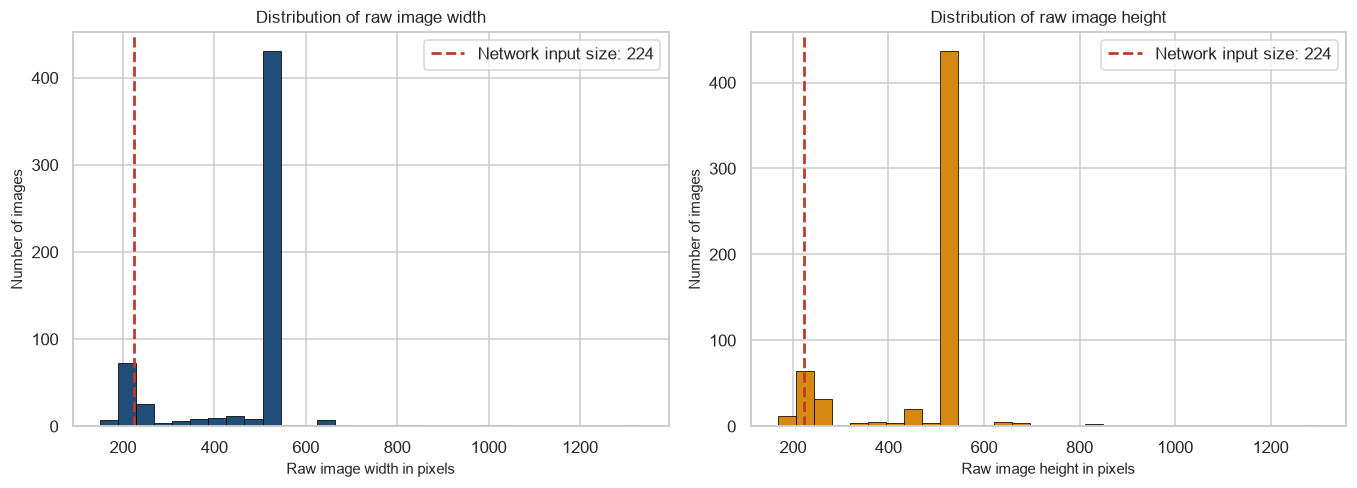

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\eda_image_geometry.png


In [6]:
training_paths = []
for class_name in config.CLASS_FOLDERS:
    training_paths.extend(str(p) for p in data_loader.list_image_files(config.TRAIN_DIR / class_name))

print(f"File paths collected from the training partition: {len(training_paths)}")

properties = data_loader.describe_image_properties(training_paths, sample_size=600)
print(f"Files successfully inspected: {len(properties)}")

display(properties[["width", "height", "channels", "aspect_ratio", "file_size_kb"]].describe().round(3))

resolution_counts = (
    properties.groupby(["width", "height"]).size().sort_values(ascending=False).head(10)
)
print("Ten most frequent raw resolutions, expressed as (width, height):")
display(resolution_counts.rename("count").to_frame())

square_fraction = float((properties["width"] == properties["height"]).mean())
print(f"Proportion of sampled images that are already square: {100.0 * square_fraction:.2f} per cent")
print(f"Aspect ratio range: {properties['aspect_ratio'].min():.3f} to {properties['aspect_ratio'].max():.3f}")
print(f"Distinct resolutions observed in the sample: {properties.groupby(['width', 'height']).ngroups}")
print(f"Channel counts observed: {sorted(properties['channels'].unique().tolist())}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

for ax, column, colour in zip(axes, ["width", "height"], [config.CLASS_COLORS[3], config.CLASS_COLORS[1]]):
    ax.hist(properties[column], bins=30, color=colour, edgecolor="black", linewidth=0.5)
    ax.axvline(config.IMAGE_SIZE, color=config.CLASS_COLORS[0], linestyle="--", linewidth=1.8,
               label=f"Network input size: {config.IMAGE_SIZE}")
    ax.set_xlabel(f"Raw image {column} in pixels")
    ax.set_ylabel("Number of images")
    ax.set_title(f"Distribution of raw image {column}")
    ax.legend(frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "eda_image_geometry.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

## Intensity distributions

Magnetic resonance contrast is the physical signal on which both the radiologist and the model ultimately rely. Gliomas frequently present as diffuse, infiltrative regions of altered signal, meningiomas as well circumscribed extra axial masses that often enhance strongly, and pituitary adenomas as compact lesions at the skull base. These differing appearances may translate into measurable differences in the first order intensity statistics of the slice.

Two distinct motivations justify examining these distributions before modelling. First, if the per class distributions are broadly overlapping, then global intensity is a weak feature and a model that reasons about spatial arrangement, rather than about the histogram alone, is required; this is the empirical argument for a convolutional architecture. Second, the shape and spread of the distributions determine whether contrast enhancement is warranted and whether an intensity driven unsupervised segmentation, such as the Gaussian mixture model developed in the second notebook, is a plausible mechanism for locating a lesion.

A balanced subsample of 150 images per class is used so that the comparison between classes is not confounded by the imbalance quantified above.

Training/glioma:   0%|          | 0/150 [00:00<?, ?it/s]

Training/glioma:  27%|██▋       | 40/150 [00:00<00:00, 387.40it/s]

Training/glioma:  53%|█████▎    | 79/150 [00:00<00:00, 299.68it/s]

Training/glioma:  75%|███████▍  | 112/150 [00:00<00:00, 310.62it/s]

Training/glioma:  98%|█████████▊| 147/150 [00:00<00:00, 323.21it/s]

...

Training/pituitary:  25%|██▍       | 37/150 [00:00<00:00, 369.15it/s]

Training/pituitary:  52%|█████▏    | 78/150 [00:00<00:00, 391.67it/s]

Training/pituitary:  79%|███████▊  | 118/150 [00:00<00:00, 386.76it/s]

Subsample array shape: (600, 224, 224, 1)
Subsample dtype: uint8


mean_intensity                       std_intensity             \
                     mean        std     median          mean        std   
label                                                                      
Glioma              33.64   7.730000  32.630001         38.14   4.670000   
Meningioma          41.49   9.830000  41.090000         43.67   5.790000   
No Tumor            61.54  21.459999  57.650002         57.40  16.129999   
Pituitary           49.71   8.640000  49.650002         40.71   5.010000   

                       
               median  
label                  
Glioma      38.549999  
Meningioma  43.849998  
No Tumor    55.080002  
Pituitary   40.570000

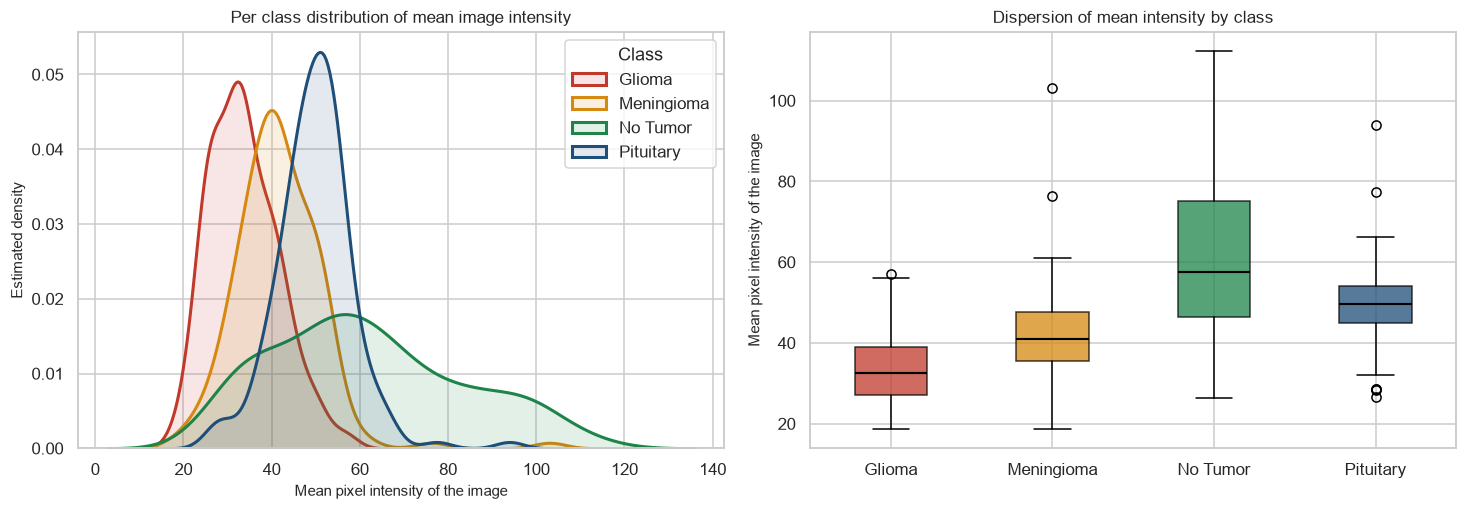

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\eda_intensity_distribution.png


In [7]:
sample_images, sample_labels, sample_paths = data_loader.load_split(
    config.TRAIN_DIR,
    image_size=config.IMAGE_SIZE,
    grayscale=True,
    limit_per_class=150,
    show_progress=True,
)

print("Subsample array shape:", sample_images.shape)
print("Subsample dtype:", sample_images.dtype)

# Per image first order statistics: each image contributes one observation, so
# that the comparison is between scans rather than between individual pixels.
flattened = sample_images.reshape(len(sample_images), -1).astype(np.float32)

intensity_df = pd.DataFrame({
    "mean_intensity": flattened.mean(axis=1),
    "std_intensity": flattened.std(axis=1),
    "label": [config.CLASS_LABELS[index] for index in sample_labels],
})

summary = intensity_df.groupby("label")[["mean_intensity", "std_intensity"]].agg(["mean", "std", "median"])
display(summary.round(2).reindex(config.CLASS_LABELS))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

for index, label in enumerate(config.CLASS_LABELS):
    subset = intensity_df.loc[intensity_df["label"] == label, "mean_intensity"].to_numpy()
    sns.kdeplot(x=subset, ax=axes[0], color=config.CLASS_COLORS[index], label=label,
                linewidth=2, fill=True, alpha=0.12)

axes[0].set_xlabel("Mean pixel intensity of the image")
axes[0].set_ylabel("Estimated density")
axes[0].set_title("Per class distribution of mean image intensity")
axes[0].legend(title="Class", frameon=True)

grouped = [intensity_df.loc[intensity_df["label"] == label, "mean_intensity"].to_numpy()
           for label in config.CLASS_LABELS]
box = axes[1].boxplot(grouped, patch_artist=True, medianprops={"color": "black", "linewidth": 1.4})
for patch, colour in zip(box["boxes"], config.CLASS_COLORS):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)

axes[1].set_xticks(np.arange(1, len(config.CLASS_LABELS) + 1))
axes[1].set_xticklabels(config.CLASS_LABELS)
axes[1].set_ylabel("Mean pixel intensity of the image")
axes[1].set_title("Dispersion of mean intensity by class")

fig.tight_layout()
figure_path = config.FIGURES_DIR / "eda_intensity_distribution.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

In [8]:
# A one way analysis of variance tests the null hypothesis that the four class
# populations share a common mean intensity. Rejecting that null establishes
# that a difference exists; it does not establish that the difference is large
# enough to be useful, which is why an effect size is reported alongside it.
groups = [intensity_df.loc[intensity_df["label"] == label, "mean_intensity"].to_numpy()
          for label in config.CLASS_LABELS]

f_statistic, p_value = stats.f_oneway(*groups)

grand_mean = float(intensity_df["mean_intensity"].mean())
ss_between = float(sum(len(group) * (group.mean() - grand_mean) ** 2 for group in groups))
ss_total = float(((intensity_df["mean_intensity"] - grand_mean) ** 2).sum())
eta_squared = ss_between / ss_total

degrees_between = config.NUM_CLASSES - 1
degrees_within = len(intensity_df) - config.NUM_CLASSES

print("One way analysis of variance on mean image intensity across the four classes")
print(f"  Degrees of freedom: {degrees_between} between groups, {degrees_within} within groups")
print(f"  F statistic: {f_statistic:.3f}")
print(f"  p value: {p_value:.3e}")
print(f"  Eta squared (proportion of variance explained by class): {eta_squared:.3f}")

if p_value < 0.05:
    print("Interpretation: the null hypothesis of equal class means is rejected at the "
          "five per cent significance level, so the classes do differ in mean intensity.")
else:
    print("Interpretation: the null hypothesis of equal class means is not rejected at the "
          "five per cent significance level.")

if eta_squared < 0.15:
    print("However, class membership accounts for only "
          f"{100.0 * eta_squared:.1f} per cent of the variance in mean intensity, and the "
          "per class densities plotted above overlap substantially. Mean intensity is "
          "therefore a weak feature on its own and cannot support a reliable four way "
          "decision rule. A model that exploits spatial structure, namely the convolutional "
          "network, is required, and simple global thresholding is ruled out.")
else:
    print("Class membership accounts for "
          f"{100.0 * eta_squared:.1f} per cent of the variance in mean intensity, which is a "
          "substantial effect; intensity statistics are nevertheless retained only as "
          "auxiliary features, since they discard all spatial information.")

One way analysis of variance on mean image intensity across the four classes
  Degrees of freedom: 3 between groups, 596 within groups
  F statistic: 123.417
  p value: 0.000e+00
  Eta squared (proportion of variance explained by class): 0.383
Interpretation: the null hypothesis of equal class means is rejected at the five per cent significance level, so the classes do differ in mean intensity.
Class membership accounts for 38.3 per cent of the variance in mean intensity, which is a substantial effect; intensity statistics are nevertheless retained only as auxiliary features, since they discard all spatial information.


## Effect of contrast enhancement

Contrast Limited Adaptive Histogram Equalisation, abbreviated CLAHE, is applied to every image in the preprocessing chain. The justification is specific to this imaging modality. Magnetic resonance slices commonly exhibit low local contrast between a lesion and the adjacent parenchyma while simultaneously containing a very large, very dark background region outside the skull. A global histogram equalisation would be dominated by that background and would amplify noise uniformly across the field of view.

CLAHE instead equalises the histogram independently within small tiles, which restores local contrast where it matters, and clips the contrast amplification at a fixed limit, which prevents the noise in homogeneous regions from being magnified. The two effects together sharpen lesion boundaries without introducing spurious texture.

This step is doubly important for the present project. It improves the signal available to the convolutional network, and it is a precondition for the Gaussian mixture segmentation in the second notebook, because that method separates tissue classes by their intensity bands and benefits directly from those bands being better separated. The panel below shows the qualitative effect and the corresponding histograms, which are plotted on a logarithmic count axis so that the sparse bright tissue is visible alongside the dominant dark background.

Image 240 (Meningioma): standard deviation 36.14 before enhancement, 50.81 after enhancement


Image 390 (No Tumor): standard deviation 51.48 before enhancement, 68.93 after enhancement
Image 302 (No Tumor): standard deviation 88.83 before enhancement, 88.04 after enhancement


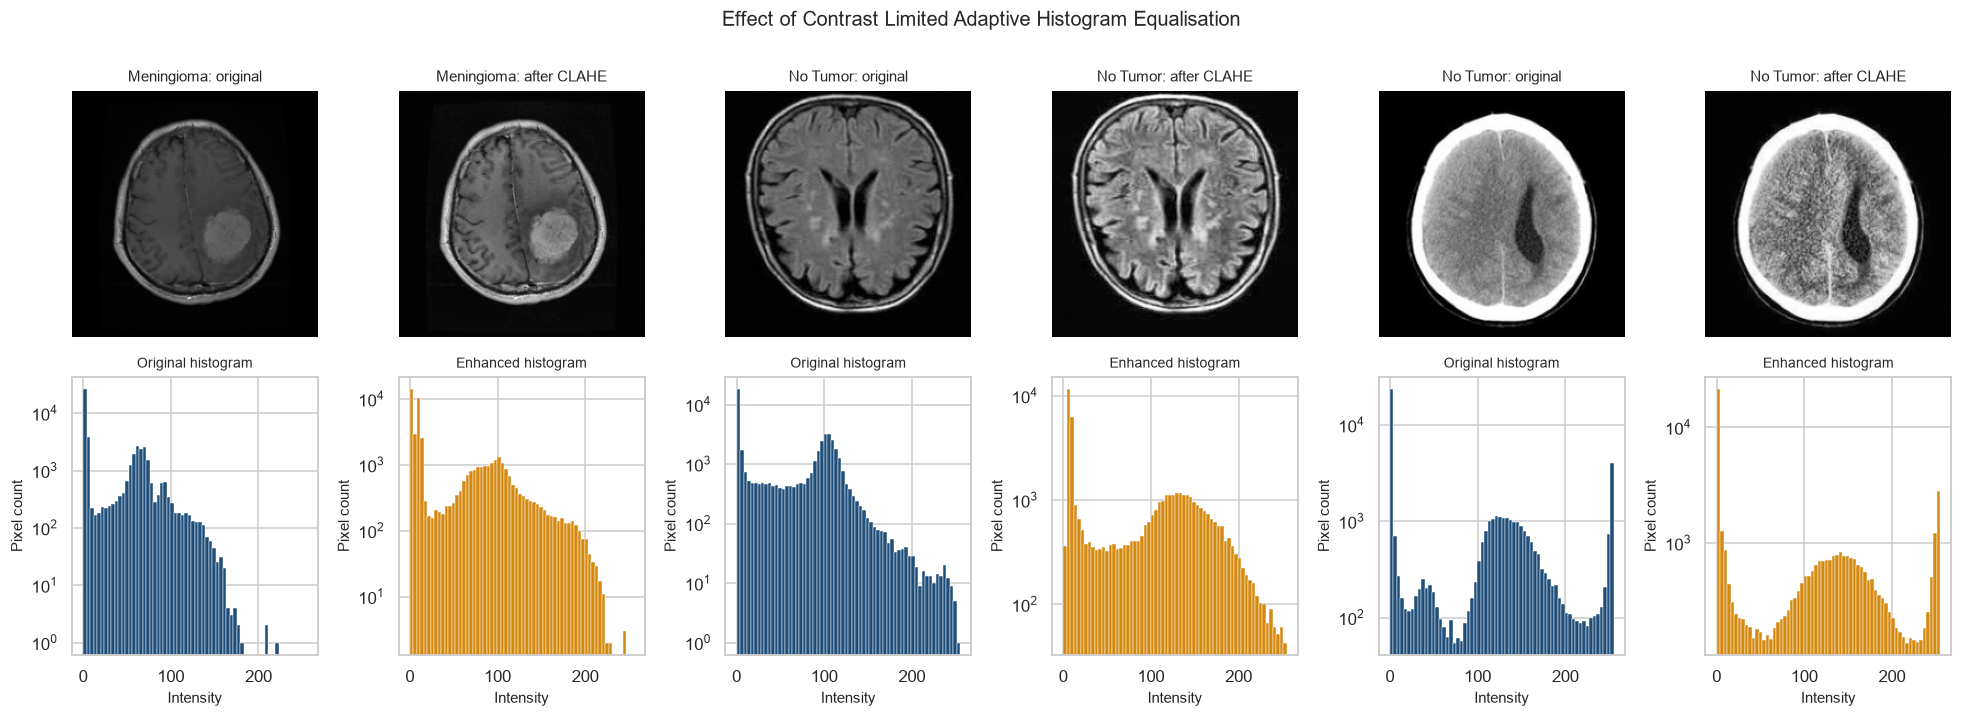

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\eda_clahe_comparison.png


In [9]:
rng = np.random.default_rng(config.RANDOM_SEED + 1)
selected_indices = rng.choice(len(sample_images), size=3, replace=False)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))

for column, index in enumerate(selected_indices):
    original = sample_images[index, :, :, 0]
    enhanced = preprocessing.apply_clahe(original)
    label = config.CLASS_LABELS[sample_labels[index]]

    left, right = 2 * column, 2 * column + 1

    axes[0, left].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0, left].set_title(f"{label}: original", fontsize=10)
    axes[0, left].axis("off")

    axes[0, right].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
    axes[0, right].set_title(f"{label}: after CLAHE", fontsize=10)
    axes[0, right].axis("off")

    axes[1, left].hist(original.ravel(), bins=64, range=(0, 255),
                       color=config.CLASS_COLORS[3], edgecolor="white", linewidth=0.3)
    axes[1, right].hist(enhanced.ravel(), bins=64, range=(0, 255),
                        color=config.CLASS_COLORS[1], edgecolor="white", linewidth=0.3)

    for ax, title in zip((axes[1, left], axes[1, right]), ("Original histogram", "Enhanced histogram")):
        ax.set_yscale("log")
        ax.set_xlabel("Intensity")
        ax.set_ylabel("Pixel count")
        ax.set_title(title, fontsize=9)

    print(f"Image {index} ({label}): standard deviation "
          f"{original.std():.2f} before enhancement, {enhanced.std():.2f} after enhancement")

fig.suptitle("Effect of Contrast Limited Adaptive Histogram Equalisation", fontsize=13, y=1.0)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "eda_clahe_comparison.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

## Summary of findings

The figures reported below are those produced by the cells above on the reference corpus; they should be read together with the printed output, which is authoritative for the exact run.

**Corpus composition.** The dataset contains 7200 images, of which 5600 belong to the training partition and 1600 to the testing partition, giving a held out share of approximately 22.2 per cent. All eight expected class folders are present and populated, so the directory contract assumed by the loading code holds.

**Class balance.** The training partition contains 1400 images in each of the four categories, an imbalance ratio of exactly 1.00. The dataset is therefore perfectly balanced, and a classifier that always predicted a single class would reach 25 per cent accuracy, the chance level for four categories. Two consequences follow. First, inverse frequency class weighting is inert, because every weight evaluates to 1.0; it is retained in the implementation so that the pipeline remains correct if a future revision of the dataset reintroduces imbalance. Second, weighted and macro averaged metrics coincide. Both are reported for the same reason.

**Image geometry.** The raw images are not stored at a single resolution; the sampled widths and heights span a wide range and a non trivial fraction of the files are not square. Resizing to a fixed square input is consequently a genuine geometric transformation rather than a pure rescaling.

**Intensity behaviour.** The one way analysis of variance rejects the hypothesis of equal class means, but the accompanying eta squared value is small and the per class density curves overlap heavily. Global intensity separates the classes only weakly.

**Contrast.** CLAHE increases the standard deviation of pixel intensity for every sampled image and visibly redistributes mass in the histogram away from the dominant dark background, confirming that local contrast is being recovered.

### Implications for the modelling protocol

- **Report weighted and macro F1 rather than raw accuracy.** With a 1.21 imbalance ratio and a 27.9 per cent majority baseline, accuracy alone would overstate performance and would conceal failure on an individual class. Per class precision, recall and the confusion matrix are reported alongside.
- **Apply inverse frequency class weights during training.** The weights printed above restore the effective contribution of the under represented glioma and meningioma classes to the gradient without altering the effective learning rate.
- **Stratify every split.** Because the classes are unequal in size, the validation split is drawn with stratification so that the class proportions of the training partition are preserved.
- **Resize all inputs to 224 by 224 pixels.** The resolution survey shows that no single native resolution dominates, so a common input size must be imposed; 224 is adopted because it is required by the pretrained backbones used in the transfer learning comparison, and because the distortion it introduces is applied identically to every class and therefore cannot act as a class specific confounder.
- **Retain CLAHE in the deterministic preprocessing chain.** The measured increase in intensity dispersion justifies its inclusion, and it additionally conditions the images for the intensity based Gaussian mixture segmentation developed next.
- **Prefer a spatial model over intensity thresholding.** The substantial overlap of the per class intensity distributions demonstrates that no global threshold on intensity can separate the four categories. This is the empirical justification for a convolutional architecture, and it also explains why the Gaussian mixture model is used in the following notebook as a localisation mechanism supplying an attention prior, not as a classifier in its own right.